# k-means clustering of basin static attributes

This notebook groups basins by their **static catchment attributes** with k-means, one clustering per cross-validation fold, so that cluster membership can be used downstream as a compact description of a basin (the "cluster ID" condition in the LightGBM comparison).

It uses only the outputs of `01_preprocessing.ipynb`: the leakage-audited static features (`data/processed/features/`) and the spatially blocked fold design (`data/processed/splits/`).

**Leakage rules followed here** (see section 9 of notebook 01 and the feasibility review):

- Within each fold, the scaler, PCA and k-means are fit on that fold's **`train` basins only**. `test` basins are only *assigned* to the nearest training centroid, as an ungauged basin would be. `buffer` basins are ignored.
- Only static attributes go into the clustering. Location (`lat`, `lon`) and flow-derived attributes are not features.
- Streamflow appears in this notebook only in section 7, to *check* whether clusters are hydrologically coherent. It never influences the clusters.

**What this notebook produces**

- `data/processed/clusters/cluster_assignments.csv`: for every fold, every `k` and every `train`/`test` basin, the cluster id and the distance to its centroid.
- `data/processed/clusters/config.json`: the settings used.
- Diagnostics: choice of `k`, cluster profiles, region composition, stability across folds, and hydrological coherence.

In [1]:
import json
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# Resolve paths from either the repository root or the notebooks folder.
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import combine_shards

PROCESSED = combine_shards.PROCESSED
SPLITS = PROCESSED / "splits"
STATIC_DIR = PROCESSED / "features"
CLUSTER_OUT = PROCESSED / "clusters"

## Parameters

All choices are collected here.

- **`K_VALUES`**: the candidate numbers of clusters carried into the modelling stage (the plan calls for three to four values). Section 3 shows the evidence for the range.
- **`PCA_VARIANCE`**: share of variance kept by PCA before k-means. The 179 numeric attributes are strongly redundant (for example, twelve monthly columns per climate variable), and k-means distances in the full space would over-weight those blocks.
- **`INCLUDE_CATEGORICAL`**: the ten `*_cl_smj` class-code columns are left out by default. Several have dozens of classes, many specific to one region, and notebook 01 flagged that they may act as near-identifiers. Set to `True` to one-hot encode them (classes rarer than `MIN_CAT_FREQ` are pooled).

In [2]:
K_VALUES = [3, 4, 6, 8]          # candidate cluster counts used downstream
K_SWEEP = range(2, 13)           # wider range, for the elbow / silhouette plots only
PCA_VARIANCE = 0.90              # fraction of variance kept by PCA
INCLUDE_CATEGORICAL = False      # one-hot the *_cl_smj class columns?
MIN_CAT_FREQ = 0.02              # pool categories rarer than this (only if INCLUDE_CATEGORICAL)
N_INIT = 25                      # k-means restarts
SEED = 780                       # same seed as notebook 01

DEMO_FOLD = 0                    # fold used for the single-fold illustrations
DEMO_K = 4                       # k used for the cluster-profile heatmap
WRITE_OUTPUTS = True             # write data/processed/clusters/
LOG_EPS = 0.01                   # mm/day, same offset as notebook 01 (flow signatures only)
TRAIN_PERIOD = ("1986-10-01", "2003-09-30")   # taken from splits/config.json below

## 1. Load the static features and the folds

The two loaders below are copied from section 9 of notebook 01, so the folds mean exactly the same thing here: `train_basins` and `test_basins` already require enough valid streamflow in the respective periods (`usable_train`, `usable_test`).

In [3]:
def load_fold(k: int, splits_dir: Path = SPLITS) -> dict:
    # Basin ids for fold k (copied from notebook 01, section 9).
    info = pd.read_csv(splits_dir / "basins.csv", index_col="gauge_id")
    r = pd.read_csv(splits_dir / "fold_roles.csv").query("fold == @k").set_index("gauge_id")
    train = r.index[(r["role"] == "train") & info.loc[r.index, "usable_train"]]
    test = r.index[(r["role"] == "test") & info.loc[r.index, "usable_test"]]
    return {"train_basins": list(train), "test_basins": list(test)}


def load_static(static_dir: Path = STATIC_DIR) -> tuple[pd.DataFrame, dict]:
    groups = json.loads((static_dir / "feature_groups.json").read_text())
    return pd.read_parquet(static_dir / "static_attributes.parquet"), groups


split_cfg = json.loads((SPLITS / "config.json").read_text())
N_FOLDS = split_cfg["n_folds"]
TRAIN_PERIOD = tuple(split_cfg["periods"]["train"])

static_df, groups = load_static()
NUMERIC, CATEGORICAL = groups["numeric"], groups["categorical"]
FEATURES = NUMERIC + (CATEGORICAL if INCLUDE_CATEGORICAL else [])
folds = {k: load_fold(k) for k in range(N_FOLDS)}

print(f"static table: {static_df.shape[0]} basins; {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features")
print(f"features used for clustering: {len(FEATURES)}   (categorical included: {INCLUDE_CATEGORICAL})")
print(f"missing values in the clustering features: {int(static_df[FEATURES].isna().sum().sum())}")
pd.DataFrame({k: {"train": len(v["train_basins"]), "test": len(v["test_basins"])} for k, v in folds.items()}).T.rename_axis("fold")

static table: 1208 basins; 179 numeric + 10 categorical features
features used for clustering: 179   (categorical included: False)
missing values in the clustering features: 0


,train,test
fold,,
0,867,241
1,905,242
2,860,242
3,889,242
4,875,241


## 2. The clustering pipeline

One function builds the whole chain: **standardise, PCA, k-means**. Because every step is a `scikit-learn` pipeline stage, `fit` learns all parameters from the training basins and `transform`/`predict` apply them unchanged to new basins. This is exactly the "refit scalers, PCA and clustering inside each fold" requirement.

The function takes the set of training basins as an argument, so the same code can later be refit on the 25/50/100 basin subsamples for the training-basin-count experiment.

In [4]:
def make_pipeline(k: int) -> Pipeline:
    # Standardise (and optionally one-hot) -> PCA -> k-means. Nothing is fit until .fit() is called.
    transformers = [("num", StandardScaler(), NUMERIC)]
    if INCLUDE_CATEGORICAL:
        transformers.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                  min_frequency=MIN_CAT_FREQ, sparse_output=False), CATEGORICAL))
    return Pipeline([
        ("prep", ColumnTransformer(transformers)),
        ("pca", PCA(n_components=PCA_VARIANCE, svd_solver="full", random_state=SEED)),
        ("kmeans", KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED)),
    ])


def fit_clusterer(train_ids: list[str], k: int) -> Pipeline:
    # Fit the whole pipeline on the given training basins only.
    return make_pipeline(k).fit(static_df.loc[train_ids, FEATURES])


def assign(pipe: Pipeline, ids: list[str]) -> pd.DataFrame:
    # Cluster id and distance to the nearest centroid for any basins (training or held-out).
    Z = pipe[:-1].transform(static_df.loc[ids, FEATURES])
    km = pipe["kmeans"]
    return pd.DataFrame({"cluster": km.predict(Z), "dist_to_centroid": km.transform(Z).min(axis=1)}, index=ids)


# How many principal components does each fold keep?
n_pc = {f: make_pipeline(2)[:-1].fit(static_df.loc[v["train_basins"], FEATURES])["pca"].n_components_
        for f, v in folds.items()}
print("principal components kept per fold:", n_pc)

principal components kept per fold: {0: np.int64(30), 1: np.int64(29), 2: np.int64(30), 3: np.int64(28), 4: np.int64(28)}


## 3. How many clusters?

For each fold we fit k-means on the training basins for `k = 2…12` and record two summaries:

- **Inertia per basin** (within-cluster sum of squares in PCA space). It always falls as `k` grows; look for where the decline flattens (the "elbow").
- **Silhouette score** (−1 to 1). Higher means basins sit closer to their own cluster than to the next nearest one. Values below about 0.25 indicate weak cluster structure.

Grey lines are the individual folds; the blue line is their mean. Red dotted lines mark the candidate `K_VALUES`.

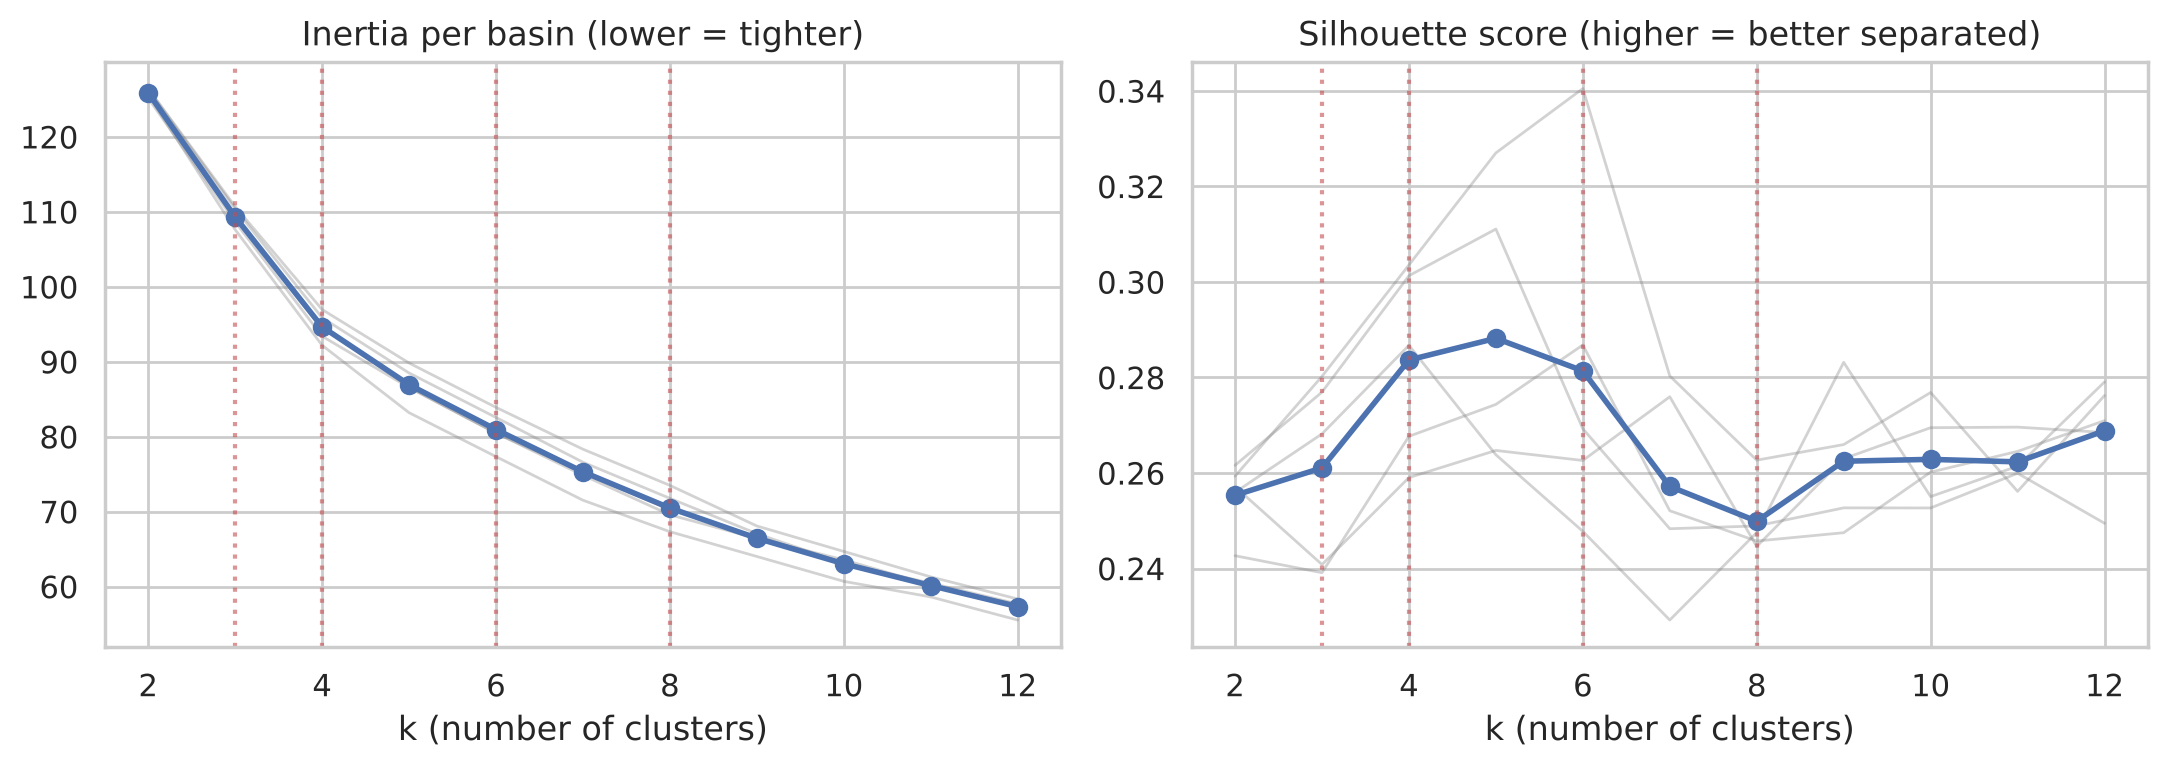

k,2,3,4,5,6,7,8,9,10,11,12
inertia_per_basin,125.903,109.329,94.653,86.929,80.945,75.301,70.478,66.446,63.036,60.125,57.315
silhouette,0.255,0.261,0.284,0.288,0.281,0.257,0.250,0.262,0.263,0.262,0.269


In [5]:
rows = []
for f, v in folds.items():
    Z = make_pipeline(2)[:-1].fit(static_df.loc[v["train_basins"], FEATURES]).transform(static_df.loc[v["train_basins"], FEATURES])
    for k in K_SWEEP:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Z)
        rows.append({"fold": f, "k": k, "inertia_per_basin": km.inertia_ / len(Z),
                     "silhouette": silhouette_score(Z, km.labels_, random_state=SEED)})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for col, ax, title in [("inertia_per_basin", axes[0], "Inertia per basin (lower = tighter)"),
                       ("silhouette", axes[1], "Silhouette score (higher = better separated)")]:
    for _, g in sweep.groupby("fold"):
        ax.plot(g["k"], g[col], color="grey", alpha=0.35, lw=1)
    m = sweep.groupby("k")[col].mean()
    ax.plot(m.index, m.values, "o-", color="C0", lw=2)
    for kv in K_VALUES:
        ax.axvline(kv, ls=":", color="C3", alpha=0.6)
    ax.set(title=title, xlabel="k (number of clusters)")
plt.tight_layout()
plt.show()

sweep.groupby("k")[["inertia_per_basin", "silhouette"]].mean().round(3).T

## 4. Fit every fold at every candidate `k`

For each fold and each `k` in `K_VALUES`, fit on the training basins and assign both the training basins and the held-out test basins. The result is one long table, which is also what downstream notebooks will read.

In [6]:
models, parts = {}, []
for f, v in folds.items():
    for k in K_VALUES:
        pipe = fit_clusterer(v["train_basins"], k)
        models[(f, k)] = pipe
        for role, ids in (("train", v["train_basins"]), ("test", v["test_basins"])):
            a = assign(pipe, ids).rename_axis("gauge_id").reset_index()
            parts.append(a.assign(fold=f, k=k, role=role))

assignments = (pd.concat(parts, ignore_index=True)
               [["fold", "k", "gauge_id", "role", "cluster", "dist_to_centroid"]])
assignments = assignments.merge(static_df[["region"]], left_on="gauge_id", right_index=True)
print(f"{len(assignments):,} rows: {N_FOLDS} folds x {len(K_VALUES)} values of k x (train + test basins)")
assignments.head()

22,416 rows: 5 folds x 4 values of k x (train + test basins)


,fold,k,gauge_id,role,cluster,dist_to_centroid,region
0,0,3,camels_01013500,train,0,10.599015,US
1,0,3,camels_01073000,train,0,10.551871,US
2,0,3,camels_01078000,train,0,6.745686,US
3,0,3,camels_01118300,train,0,8.517493,US
4,0,3,camels_01121000,train,0,7.679618,US


In [7]:
# Sanity checks: every fold/k has all of its basins assigned, test basins are never in the fit, ids are valid.
for (f, k), g in assignments.groupby(["fold", "k"]):
    assert set(g.loc[g.role == "train", "gauge_id"]) == set(folds[f]["train_basins"])
    assert set(g.loc[g.role == "test", "gauge_id"]) == set(folds[f]["test_basins"])
    assert not set(g.loc[g.role == "train", "gauge_id"]) & set(g.loc[g.role == "test", "gauge_id"])
    assert g["cluster"].between(0, k - 1).all()
    assert models[(f, k)]["kmeans"].n_features_in_ == n_pc[f]
print("assignment checks passed")

if WRITE_OUTPUTS:
    CLUSTER_OUT.mkdir(parents=True, exist_ok=True)
    assignments.drop(columns="region").round({"dist_to_centroid": 4}).to_csv(CLUSTER_OUT / "cluster_assignments.csv", index=False)
    (CLUSTER_OUT / "config.json").write_text(json.dumps({
        "method": "StandardScaler -> PCA -> KMeans, fit on each fold's train basins only",
        "k_values": K_VALUES, "pca_variance": PCA_VARIANCE, "n_components_per_fold": {str(f): int(n) for f, n in n_pc.items()},
        "include_categorical": INCLUDE_CATEGORICAL, "min_cat_freq": MIN_CAT_FREQ, "n_init": N_INIT, "seed": SEED,
        "n_features": len(FEATURES), "n_folds": N_FOLDS, "columns": list(assignments.columns.drop("region")),
    }, indent=2))
    print("wrote", (CLUSTER_OUT / "cluster_assignments.csv").relative_to(REPO), "and config.json")

assignment checks passed
wrote data/processed/clusters/cluster_assignments.csv and config.json


## 5. What do the clusters look like?

### Size and region composition

The static attributes include climate and land-cover descriptors that differ systematically between the US and Australia, so a worry is that k-means mostly **re-discovers the country**. Two summaries quantify it, averaged over folds, on the training basins:

- **Region purity**: the share of basins that belong to their cluster's majority region (1.0 = every cluster is entirely US or entirely AUS; the baseline is the larger region's share, about 0.55).
- **ARI vs region**: adjusted Rand index between cluster labels and the US/AUS split (1 = identical, 0 = unrelated).

In [8]:
tr = assignments[assignments.role == "train"]

def region_purity(g):
    return g.groupby("cluster")["region"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(g)

comp = pd.DataFrame([{"k": k, "fold": f, "purity": region_purity(g),
                      "ARI vs region": adjusted_rand_score(g["region"], g["cluster"]),
                      "smallest cluster": g["cluster"].value_counts().min()}
                     for (k, f), g in tr.groupby(["k", "fold"])])
base_share = static_df["region"].value_counts(normalize=True).max()
print(f"baseline purity (larger region's share of all basins): {base_share:.2f}")
comp.groupby("k")[["purity", "ARI vs region", "smallest cluster"]].mean().round(2)

baseline purity (larger region's share of all basins): 0.55


,purity,ARI vs region,smallest cluster
k,,,
3,0.97,0.70,164.6
4,0.94,0.48,138.4
6,0.99,0.41,65.0
8,0.99,0.28,55.4


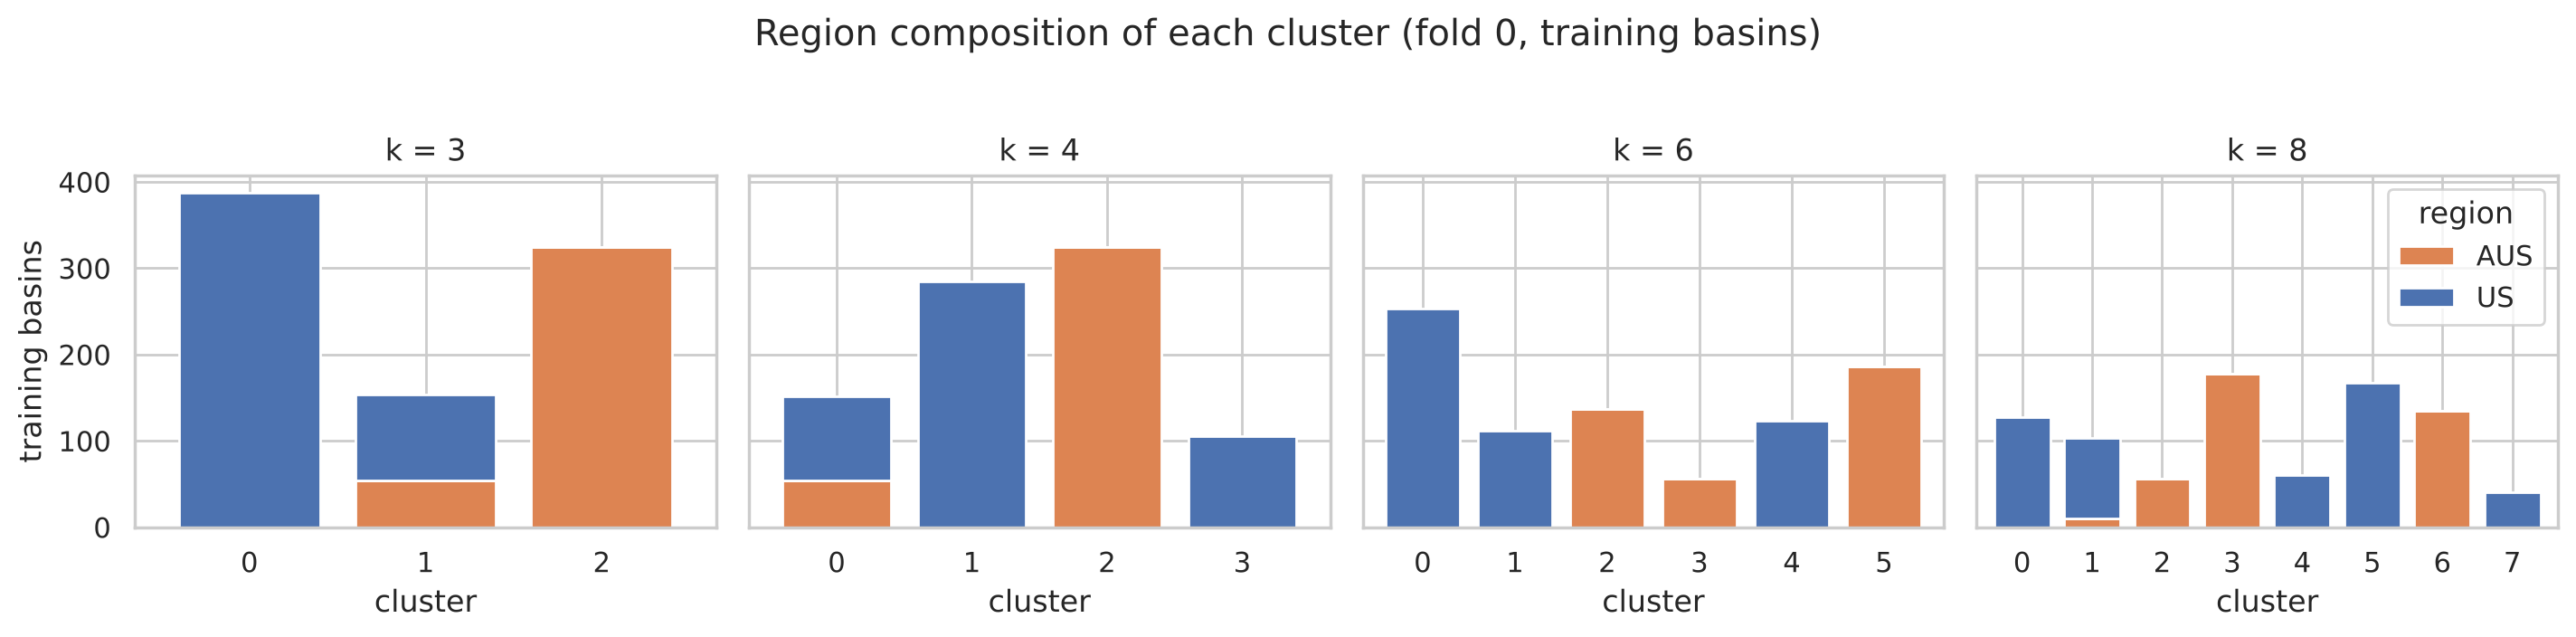

In [9]:
d = tr[tr.fold == DEMO_FOLD]
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(3.6 * len(K_VALUES), 3.4), sharey=True)
for ax, k in zip(axes, K_VALUES):
    ct = pd.crosstab(d.loc[d.k == k, "cluster"], d.loc[d.k == k, "region"])
    ct.plot.bar(stacked=True, ax=ax, color={"US": "C0", "AUS": "C1"}, legend=(k == K_VALUES[-1]), width=0.8)
    ax.set(title=f"k = {k}", xlabel="cluster", ylabel="training basins" if k == K_VALUES[0] else "")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle(f"Region composition of each cluster (fold {DEMO_FOLD}, training basins)", y=1.03)
plt.tight_layout()
plt.show()

### Cluster profiles

Which attributes define each cluster? The heatmap shows, for the demo fold and `DEMO_K`, the cluster mean of a few interpretable attributes as a **z-score** relative to the training basins (red = above average, blue = below). The attributes are only for reading the clusters; the clustering itself used all features.

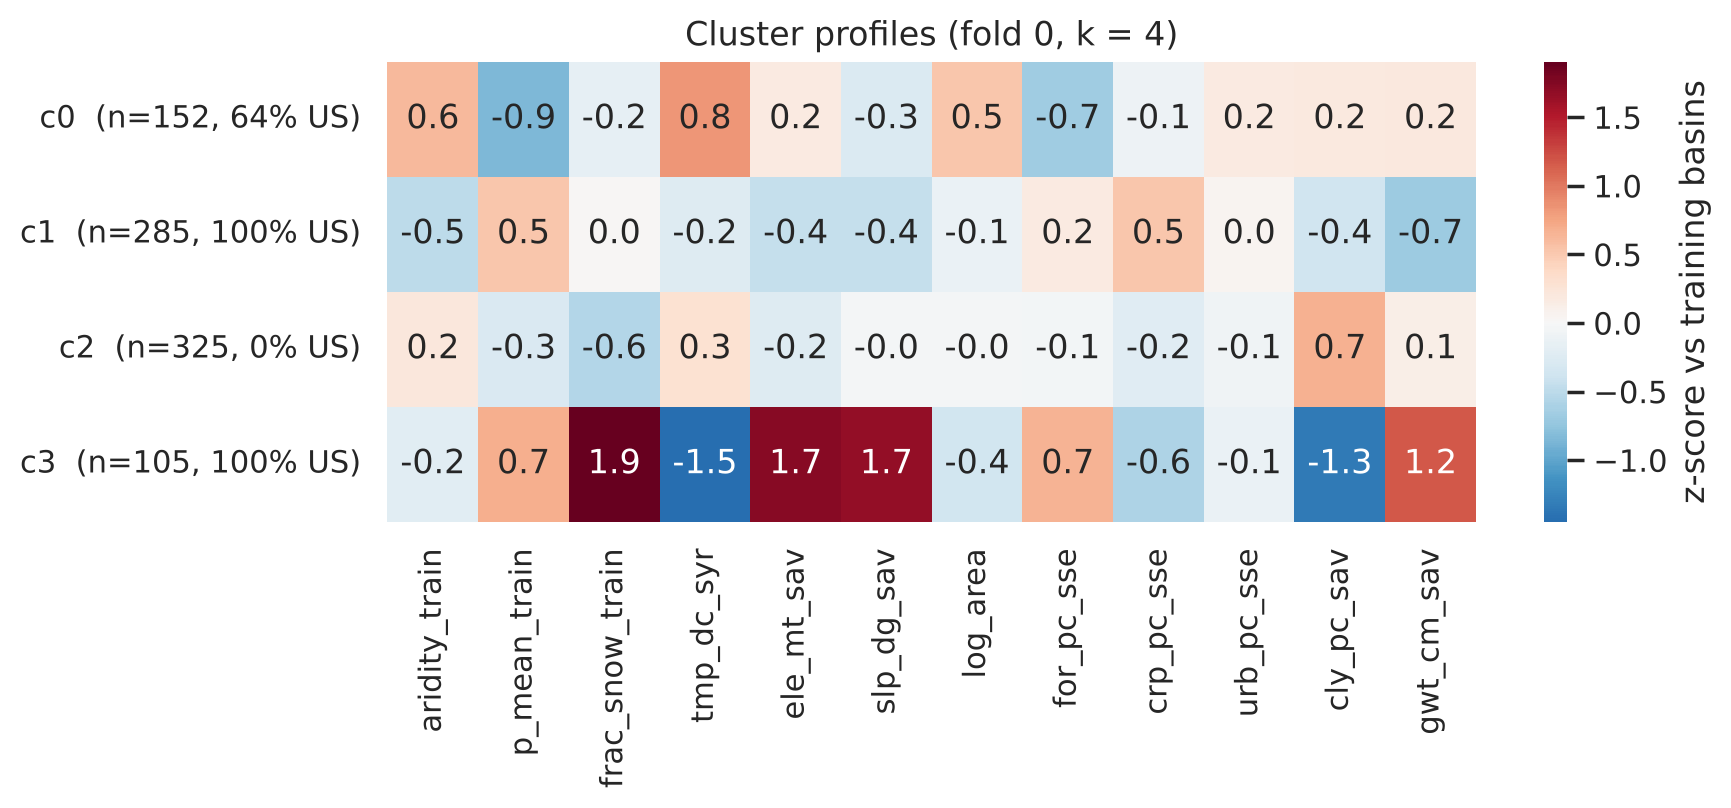

In [10]:
PROFILE_COLS = ["aridity_train", "p_mean_train", "frac_snow_train", "tmp_dc_syr", "ele_mt_sav", "slp_dg_sav",
                "log_area", "for_pc_sse", "crp_pc_sse", "urb_pc_sse", "cly_pc_sav", "gwt_cm_sav"]
PROFILE_COLS = [c for c in PROFILE_COLS if c in static_df.columns]

ids = folds[DEMO_FOLD]["train_basins"]
X = static_df.loc[ids, PROFILE_COLS]
zs = (X - X.mean()) / X.std()
lab = d[d.k == DEMO_K].set_index("gauge_id").loc[ids, "cluster"]
prof = zs.groupby(lab).mean()
sizes = lab.value_counts().sort_index()
us_share = static_df.loc[ids, "region"].eq("US").groupby(lab).mean().sort_index()
prof.index = [f"c{c}  (n={sizes[c]}, {us_share[c]:.0%} US)" for c in prof.index]

fig, ax = plt.subplots(figsize=(9, 0.55 * len(prof) + 2))
sns.heatmap(prof, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar_kws={"label": "z-score vs training basins"}, ax=ax)
ax.set(title=f"Cluster profiles (fold {DEMO_FOLD}, k = {DEMO_K})")
plt.tight_layout()
plt.show()

## 6. Stability and extrapolation

**Stability across folds.** Each fold clusters a different (overlapping) set of training basins, so cluster *numbers* are arbitrary, but the *grouping* should agree. For every pair of folds, we take the basins that were training basins in both and compute the adjusted Rand index between the two labelings (1 = same grouping, 0 = unrelated).

**Extrapolation of test basins.** A test basin is assigned to its nearest training centroid however far away it is. If held-out basins are systematically farther from their centroid than training basins are, the cluster ID is a weaker description for them. We report how many test basins sit beyond the 95th percentile of the training distances (about 5% would be expected if test basins resembled training basins).

In [11]:
stab = []
for k in K_VALUES:
    for f1, f2 in combinations(range(N_FOLDS), 2):
        a = tr[(tr.k == k) & (tr.fold == f1)].set_index("gauge_id")["cluster"]
        b = tr[(tr.k == k) & (tr.fold == f2)].set_index("gauge_id")["cluster"]
        common = a.index.intersection(b.index)
        stab.append({"k": k, "pair": (f1, f2), "shared basins": len(common), "ARI": adjusted_rand_score(a[common], b[common])})
stab = pd.DataFrame(stab)

ext = []
for (k, f), g in assignments.groupby(["k", "fold"]):
    dtr, dte = g.loc[g.role == "train", "dist_to_centroid"], g.loc[g.role == "test", "dist_to_centroid"]
    ext.append({"k": k, "fold": f, "median dist (train)": dtr.median(), "median dist (test)": dte.median(),
                "test beyond train p95": (dte > dtr.quantile(0.95)).mean()})
ext = pd.DataFrame(ext)

out = pd.concat([stab.groupby("k")["ARI"].agg(["mean", "min"]).add_prefix("ARI ").round(2),
                 ext.groupby("k")[["median dist (train)", "median dist (test)", "test beyond train p95"]].mean().round(2)], axis=1)
out

,ARI mean,ARI min,median dist (train),median dist (test),test beyond train p95
k,,,,,
3,0.63,0.44,8.21,8.66,0.09
4,0.81,0.71,7.61,8.24,0.09
6,0.72,0.55,6.95,7.61,0.09
8,0.69,0.53,6.22,7.26,0.10


## 7. Are the clusters hydrologically coherent?

The feasibility review warns that physically similar catchments are not always hydrologically similar, so tidy clusters in attribute space may not group basins that *behave* alike. We check this directly with five streamflow signatures per basin, computed from **training-period flow only** (1986-10 to 2003-09):

| Signature | Meaning |
| --- | --- |
| `log_mean_q` | mean of log daily flow (overall wetness; zero flows set by `LOG_EPS`) |
| `log_spread` | 95th minus 5th percentile of log flow (how variable the flow is) |
| `log_cv_q` | log of the coefficient of variation of daily flow |
| `zero_flow_frac` | share of days with zero flow (intermittency) |
| `lag1_autocorr` | lag-1 autocorrelation of log flow (smooth versus flashy response) |

Two measures, averaged over folds:

- **η² (training basins)**: the share of a signature's variance explained by cluster membership (0 = none, 1 = all). Even random labels give about (k−1)/(n−1), which is small here, so values well above that mean the clusters carry hydrological information.
- **Out-of-sample R² (test basins)**: predict each test basin's signature with the mean signature of the *training* basins in its assigned cluster. R² is relative to predicting the overall training mean (0 = no better; negative = worse). This is the ungauged use case in miniature.

The baseline column **region only** uses just the US/AUS label, so the clusters have to beat what the country alone explains. The signatures are for this check only. They are never used to build the clusters.

In [12]:
def flow_signatures(subsets=("camels", "camelsaus"), period=TRAIN_PERIOD, eps=LOG_EPS) -> pd.DataFrame:
    # Per-basin streamflow signatures over the training period (diagnostics only, never clustering inputs).
    frames = []
    for s in subsets:
        ts = combine_shards.load_timeseries(s, columns=["streamflow"])
        ts["date"] = pd.to_datetime(ts["date"])
        ts = ts[(ts["date"] >= period[0]) & (ts["date"] <= period[1])].dropna(subset=["streamflow"])
        frames.append(ts[["gauge_id", "streamflow"]])
    ts = pd.concat(frames, ignore_index=True)
    ts["lq"] = np.log(ts["streamflow"].clip(lower=0) + eps)
    ts["zero"] = ts["streamflow"] <= 0
    g = ts.groupby("gauge_id")
    return pd.DataFrame({
        "log_mean_q": g["lq"].mean(),
        "log_spread": g["lq"].quantile(0.95) - g["lq"].quantile(0.05),
        "log_cv_q": np.log(g["streamflow"].std() / g["streamflow"].mean()),
        "zero_flow_frac": g["zero"].mean(),
        "lag1_autocorr": g["lq"].apply(lambda s: s.autocorr(1)),
    })

signatures = flow_signatures().replace([np.inf, -np.inf], np.nan)
signatures = signatures.reindex(static_df.index)
print("basins with signatures:", int(signatures.notna().all(axis=1).sum()), "of", len(signatures))
signatures.describe().round(2).T

basins with signatures: 1208 of 1208


,count,mean,std,min,25%,50%,75%,max
log_mean_q,1208.0,-1.55,1.48,-4.58,-2.80,-1.41,-0.38,1.95
log_spread,1208.0,3.82,1.14,0.00,3.04,3.78,4.57,7.01
log_cv_q,1208.0,0.97,0.68,-1.27,0.46,0.88,1.44,3.39
zero_flow_frac,1208.0,0.14,0.23,0.00,0.00,0.00,0.19,0.99
lag1_autocorr,1208.0,0.95,0.04,0.49,0.94,0.96,0.98,1.00


In [13]:
def eta_squared(y: pd.Series, labels: pd.Series) -> float:
    # Share of the variance of y explained by group membership.
    sst = ((y - y.mean()) ** 2).sum()
    ssb = ((y.groupby(labels).transform("mean") - y.mean()) ** 2).sum()
    return ssb / sst if sst > 0 else np.nan


def oos_r2(y_tr, lab_tr, y_te, lab_te) -> float:
    # R^2 of predicting a test basin with its assigned cluster's training mean, relative to the overall training mean.
    pred = lab_te.map(y_tr.groupby(lab_tr).mean())
    return 1 - ((y_te - pred) ** 2).sum() / ((y_te - y_tr.mean()) ** 2).sum()


region = static_df["region"]
res = []
for f, v in folds.items():
    for sig in signatures.columns:
        y = signatures[sig].dropna()
        tr_ids = [b for b in v["train_basins"] if b in y.index]
        te_ids = [b for b in v["test_basins"] if b in y.index]
        schemes = {"region only": (region[tr_ids], region[te_ids])}
        for k in K_VALUES:
            g = assignments[(assignments.fold == f) & (assignments.k == k)].set_index("gauge_id")["cluster"]
            schemes[f"k={k}"] = (g[tr_ids], g[te_ids])
        for name, (ltr, lte) in schemes.items():
            res.append({"fold": f, "signature": sig, "scheme": name,
                        "eta2": eta_squared(y[tr_ids], ltr),
                        "r2_test": oos_r2(y[tr_ids], ltr, y[te_ids], lte)})
res = pd.DataFrame(res)
order = ["region only"] + [f"k={k}" for k in K_VALUES]

n_train = np.mean([len(v["train_basins"]) for v in folds.values()])
print("expected eta^2 for random labels ~ (k-1)/(n-1):", {k: round((k - 1) / (n_train - 1), 3) for k in K_VALUES})

print("\nEta-squared on training basins (mean over folds)")
display(res.pivot_table(index="signature", columns="scheme", values="eta2", aggfunc="mean")[order].round(2))
print("Out-of-sample R^2 on test basins (mean over folds)")
display(res.pivot_table(index="signature", columns="scheme", values="r2_test", aggfunc="mean")[order].round(2))

expected eta^2 for random labels ~ (k-1)/(n-1): {3: np.float64(0.002), 4: np.float64(0.003), 6: np.float64(0.006), 8: np.float64(0.008)}

Eta-squared on training basins (mean over folds)


scheme,region only,k=3,k=4,k=6,k=8
signature,,,,,
lag1_autocorr,0.00,0.08,0.14,0.16,0.16
log_cv_q,0.18,0.30,0.40,0.44,0.47
log_mean_q,0.20,0.35,0.45,0.55,0.66
log_spread,0.01,0.02,0.04,0.06,0.07
zero_flow_frac,0.12,0.21,0.34,0.39,0.45


Out-of-sample R^2 on test basins (mean over folds)


scheme,region only,k=3,k=4,k=6,k=8
signature,,,,,
lag1_autocorr,-0.01,0.03,0.14,0.11,0.09
log_cv_q,0.14,0.25,0.34,0.36,0.36
log_mean_q,0.19,0.28,0.40,0.47,0.59
log_spread,0.01,0.03,0.01,0.02,0.01
zero_flow_frac,0.10,0.23,0.31,0.34,0.44


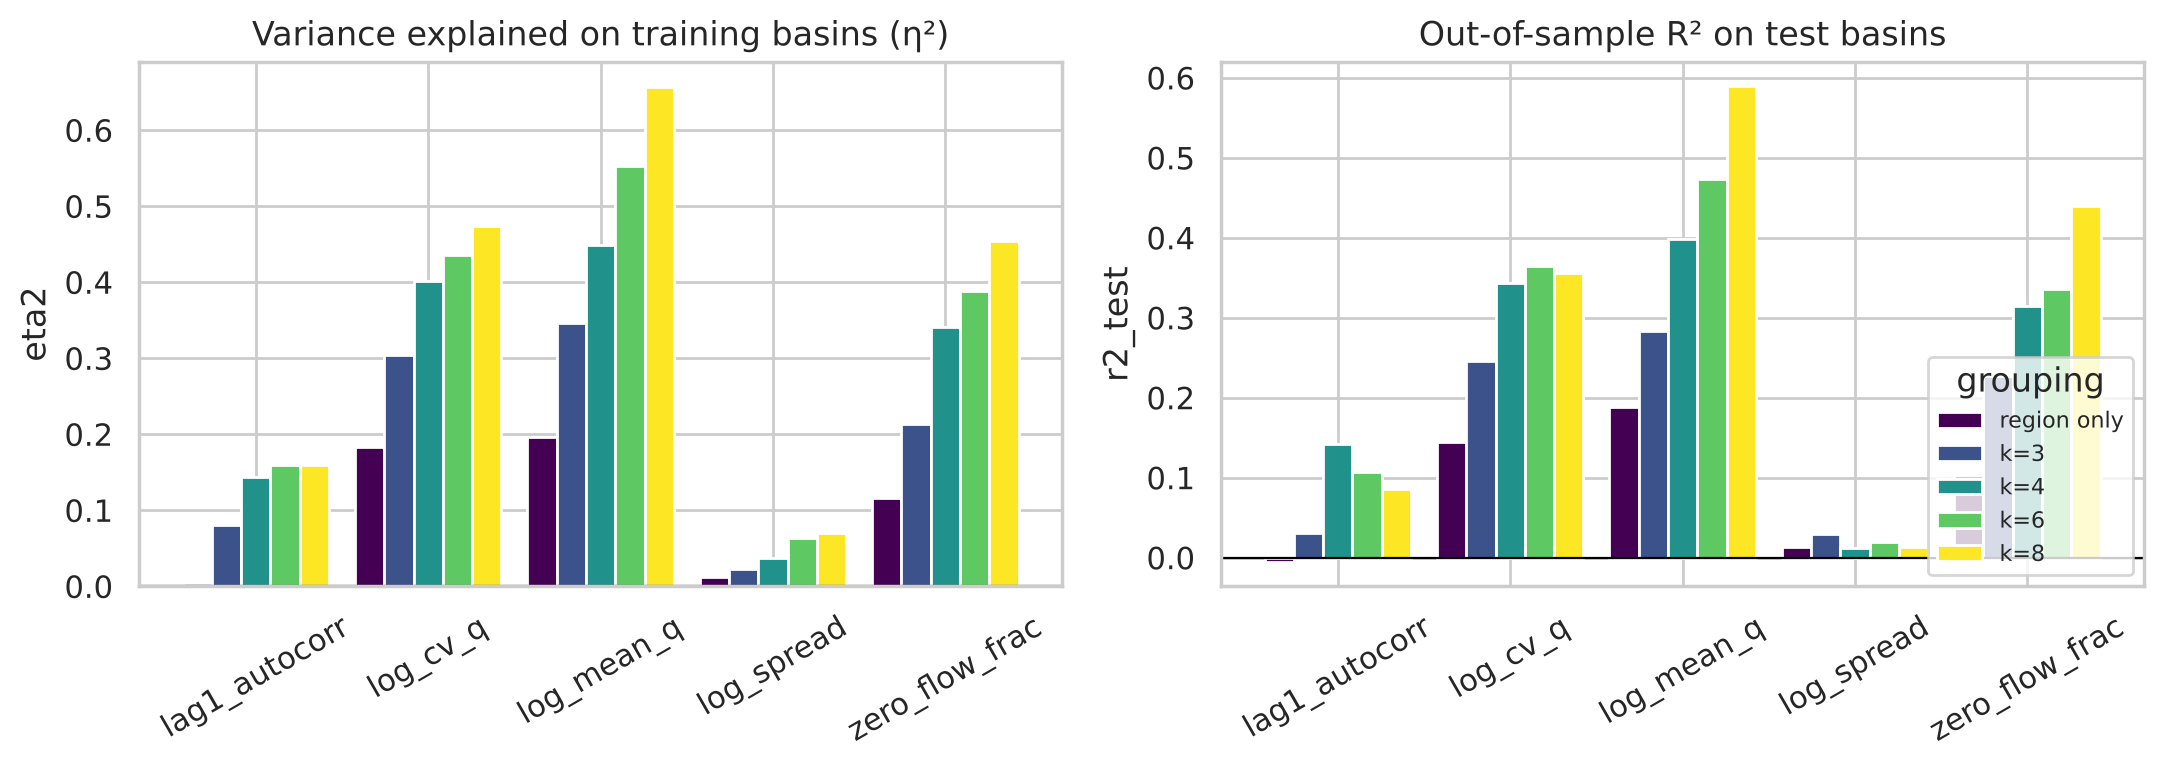

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, col, title in [(axes[0], "eta2", "Variance explained on training basins (η²)"),
                       (axes[1], "r2_test", "Out-of-sample R² on test basins")]:
    p = res.pivot_table(index="signature", columns="scheme", values=col, aggfunc="mean")[order]
    p.plot.bar(ax=ax, width=0.85, colormap="viridis")
    ax.set(title=title, xlabel="", ylabel=col)
    ax.tick_params(axis="x", rotation=30)
    ax.axhline(0, color="black", lw=0.8)
axes[0].get_legend().remove()
axes[1].legend(title="grouping", fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 8. Using the clusters downstream

For fold `f` and cluster count `k`, `cluster_assignments.csv` gives each training and test basin's cluster id. Use it as the "cluster ID" input for that fold's LightGBM run. Because the cluster id is a categorical code, pass it to LightGBM as a `category`, not a number. Never compare ids across folds or values of `k`; they are arbitrary labels.

```python
assign = pd.read_csv("data/processed/clusters/cluster_assignments.csv")
fold0_k4 = assign.query("fold == 0 and k == 4").set_index("gauge_id")["cluster"]
```

**For the training-basin-count experiment (25/50/100/all):** the cluster model must be refit on each subsample of the fold's training basins, not reused from the full-size fit. `fit_clusterer(subsample_ids, k)` and `assign(pipe, test_ids)` above do exactly that.